# Dataset Description
## Countries with highest military expenditure as share of GDP

**Source**: [SIPRI Military Expenditure Database](https://www.sipri.org/databases/milex)

# Code
## Imports

In [32]:
import pandas as pd
import matplotlib.pyplot as plt

## Load data

In [33]:
path = "./data/latin_america_share_of_gdp.csv"

df = pd.read_csv(path, encoding="utf-8", na_values=0)

## Clean Data

In [34]:
df_f = df[df["Year"].eq(2025)]

df_f["Share_of_GDP"] = df_f["Share_of_GDP"] * 100

df_f = df_f.sort_values(by="Share_of_GDP", ascending=True)
df_f.dropna(inplace=True)

## Plot

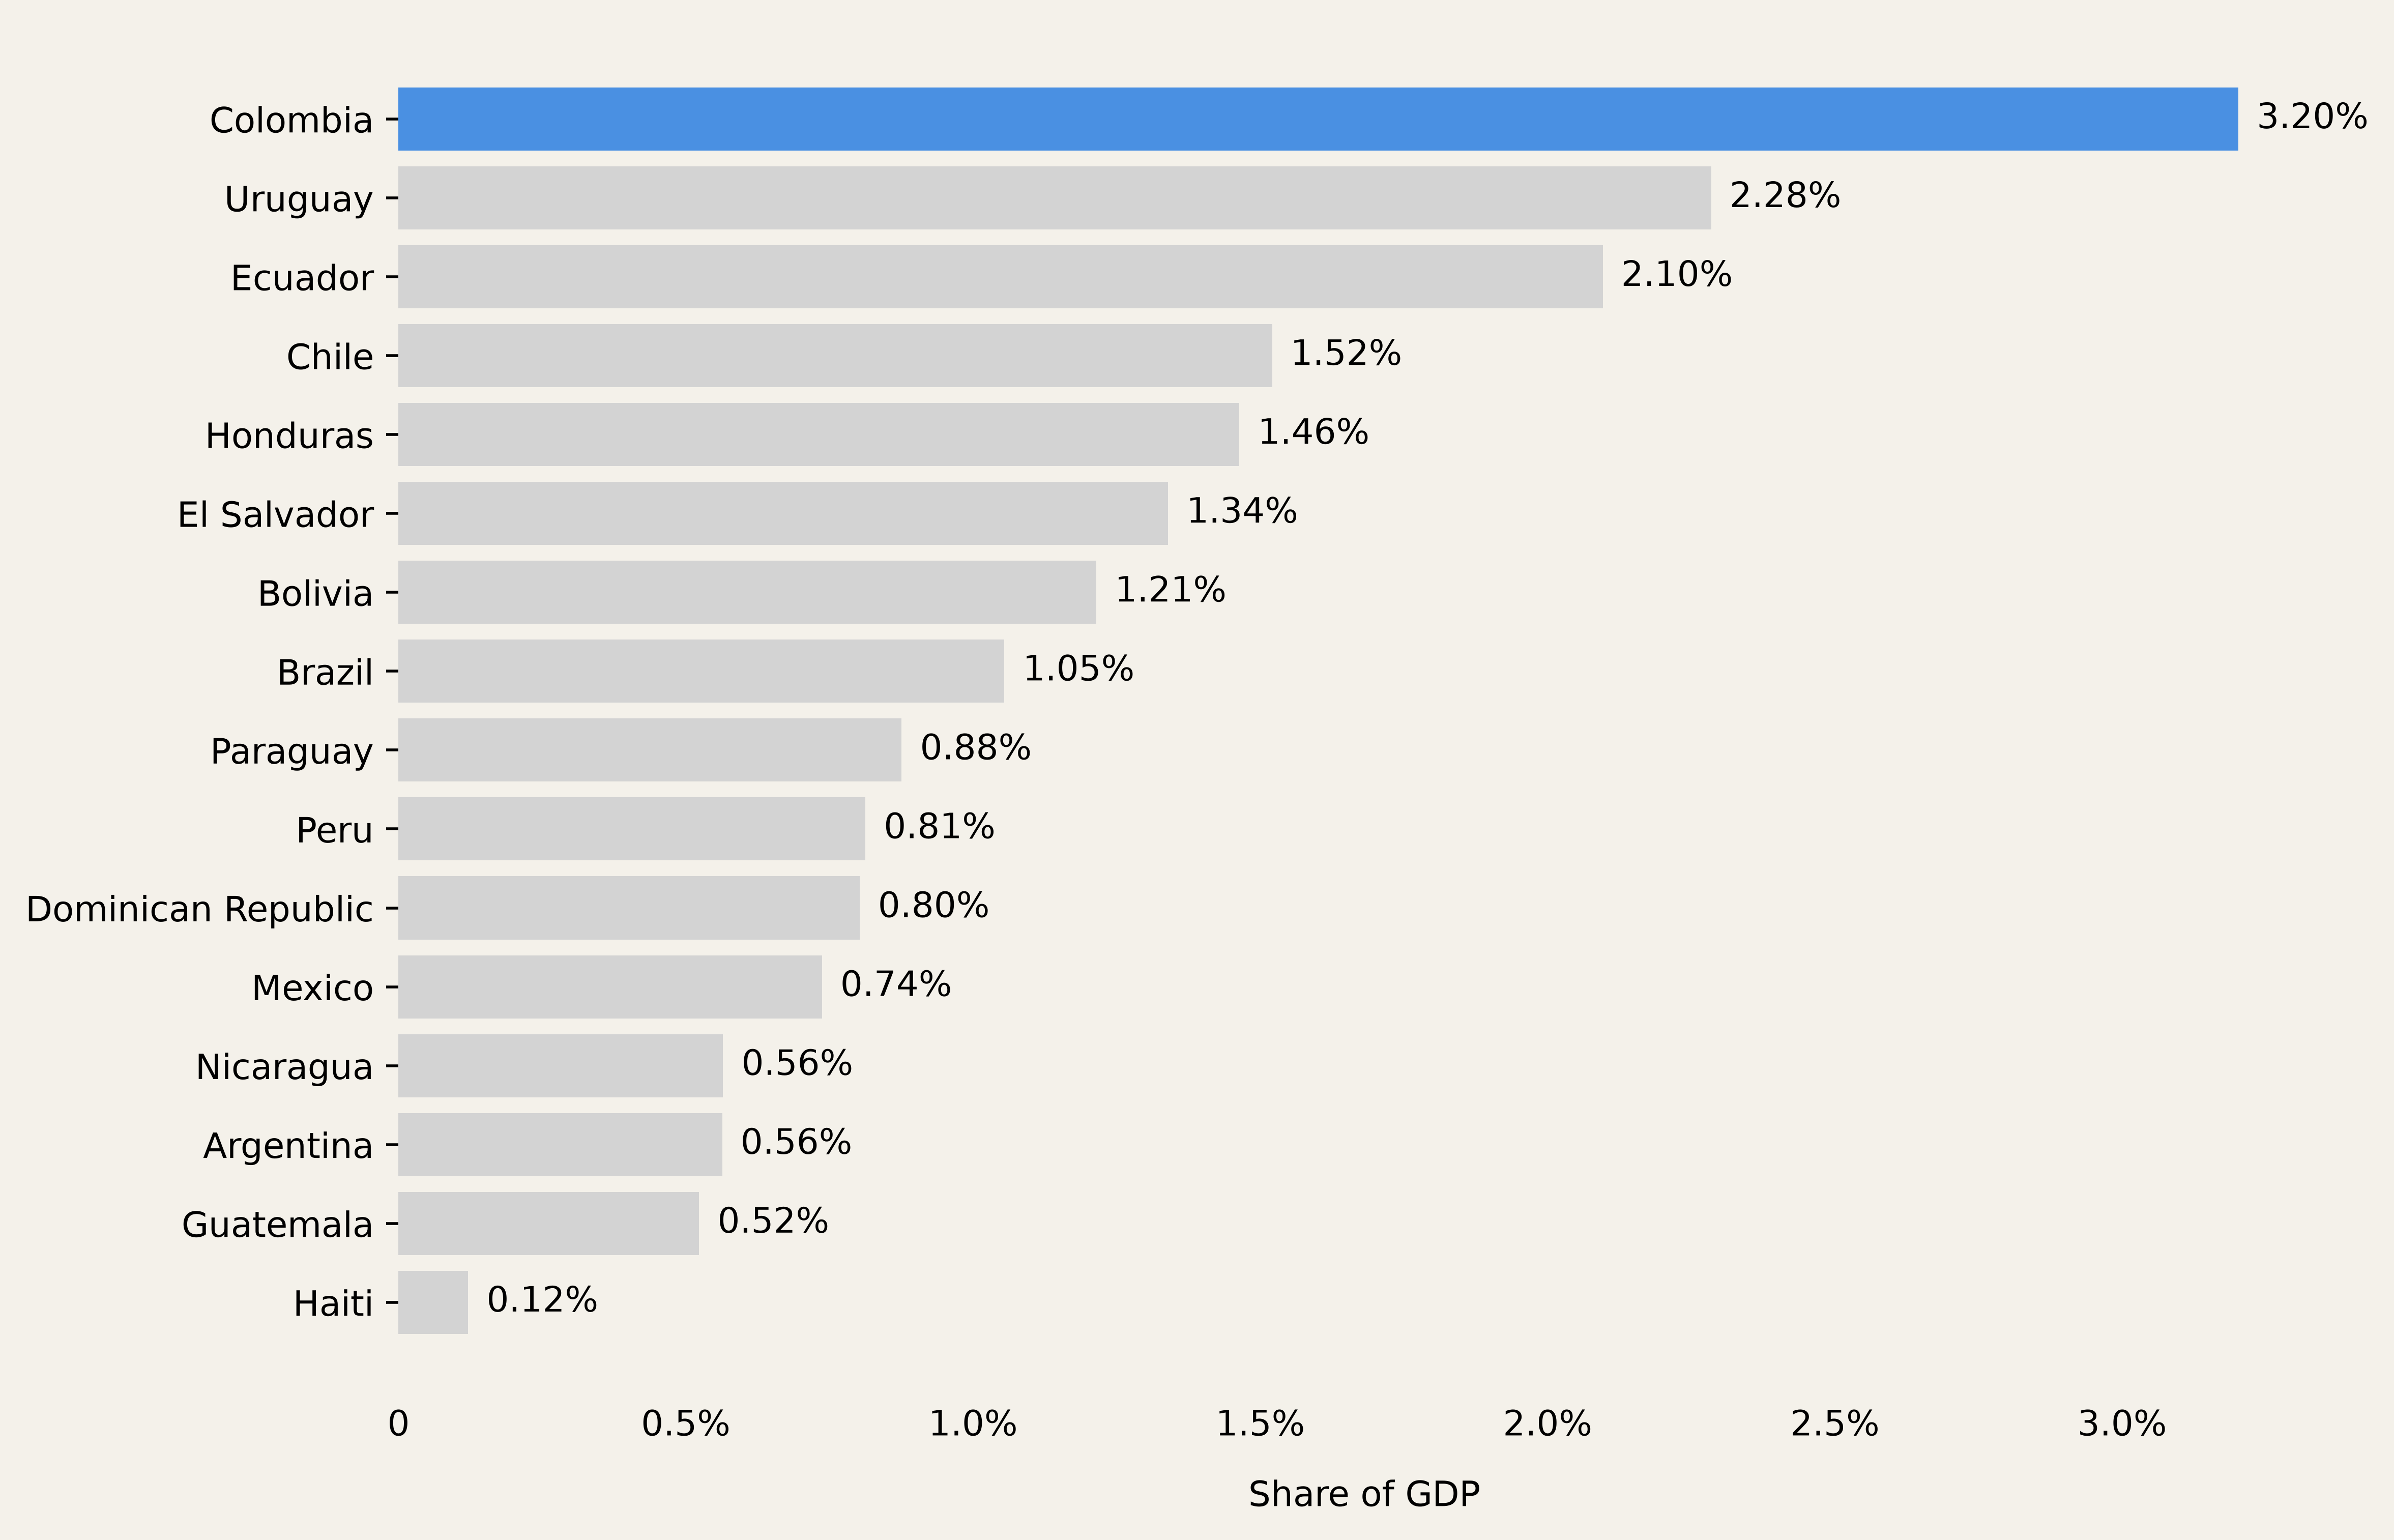

In [43]:
background = "#F4F1EA"
colombia = "#4a90e2"

plt.figure(figsize=(9.8, 7.0), dpi=500, facecolor=background)
plt.gca().set_facecolor(background)

colors = [colombia if c.lower() == "colombia" else "#D3D3D3" for c in df_f.Country]

bars = plt.barh(df_f.Country, df_f.Share_of_GDP, color=colors)
offset = df_f.Share_of_GDP.max() * 0.01
for b, v in zip(bars, df_f.Share_of_GDP):
    plt.text(v + offset, b.get_y() + b.get_height() / 2, f"{v:,.2f}%", va="center")

for side in ["top", "bottom", "left", "right"]:
    plt.gca().spines[side].set_visible(False)

plt.tick_params(axis="x", length=0)

plt.gca().xaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda x, _: f"{x}%" if x != 0  else "0"
    )
)

plt.xlabel("Share of GDP", labelpad=10, fontsize=10)

plt.show()